# 02. Queue-Reactive & State-Dependent Hawkes Stylized Facts, Empirical LOBSTER Calibration & Ogata Goodness-of-Fit

**Repository**: `queue-reactive-book`  
**References**:
- Huang, W., Lehalle, C.-A., & Rosenbaum, M. (2015). *Simulating and analyzing order book data: The queue-reactive model*. **JASA**, 110(509), 107-122.
- Wu, P., Rambaldi, M., Muzy, J.-F., & Bacry, E. (2019). *Queue-reactive Hawkes models for the order flow*. **arXiv:1901.08938**.
- Bodor, H., & Carlier, L. (2024). *The Queue-Reactive Model: Structural Properties, Empirical Foundations, and Extensions*. **arXiv:2405.18594**.
- Noble, S., Rosenbaum, M., & Souilmi, O. (2026). *Queue-Reactive Limit Order Book Simulation: An Empirical Intensity Table Approach*. **arXiv:2603.24137**.

---

## Executive Summary

In this notebook, we bridge the empirical L2/L3 datasets curated in `data/` (`LOBSTER` 2012-06-21 5-level message and orderbook files for `AAPL`, `AMZN`, `GOOG`, `INTC`, `MSFT`, and `FI-2010`) with the C++20 `sim::QueueReactiveProcess` engine:
1. **Empirical LOBSTER Calibration**: We inspect the calibrated HLR curves, level-specific Median Event Sizes (MES), and the 525-cell (`21 x 5 x 5`) Noble-Rosenbaum (2026) 3D intensity surface (`data/hlr_calibrated_5level.json` & `.csv`).
2. **Birth-Death Stationary Invariant Queue Distribution (`Theorem 2.1`, HLR 2015)**: We compare the analytical birth-death invariant distribution $\pi_i(n) \propto \prod_{k=1}^n \frac{\lambda_i^L(k-1)}{\lambda_i^C(k) + \lambda_i^M(k)}$ (with ergodic damping $\theta_{\text{ergodic}} > 0$) against simulated L1 queue depth histograms.
3. **Ogata's Time-Rescaling Theorem Goodness-of-Fit**: Under exact Ogata thinning (`next_event_ogata_thinning`), the integrated conditional intensities $\tau_k = \int_{t_{k-1}}^{t_k} \Lambda(s)\,\mathrm{d}s$ must follow a unit-rate exponential distribution $\text{Exp}(1)$. We verify this via Q-Q plots and the Kolmogorov-Smirnov test.
4. **Microstructure Stylized Facts**: Signature plot (realized volatility vs sampling horizon) and trade-sign / order-flow autocorrelation decay.


In [1]:
import sys
import json
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(pathlib.Path.cwd()))
import qrlob_notebook_utils as qru

qru.apply_publication_style()

calib_path = qru.DATA_DIR / "hlr_calibrated_5level.json"
calib_data = json.loads(calib_path.read_text(encoding="ascii"))
print("Loaded calibrated HLR + Noble-Rosenbaum 3D parameters from:", calib_path.name)
print("Tickers calibrated:", list(calib_data["ticker_summaries"].keys()))
print("Total empirical events:", calib_data["total_events_calibrated"])


Loaded calibrated HLR + Noble-Rosenbaum 3D parameters from: hlr_calibrated_5level.json
Tickers calibrated: ['AAPL', 'AMZN', 'GOOG', 'INTC', 'MSFT']
Total empirical events: 50000


## 1. Empirical LOBSTER 5-Level Summary & Noble-Rosenbaum (2026) 3D Intensity Surface

Let us examine the per-ticker calibration summary (`AAPL`, `AMZN`, `GOOG`, `INTC`, `MSFT`) and visualize the calibrated 3D intensity surface $\lambda^e(I_t, S_t, Q_t)$ across the 21 L1 imbalance bins $I_t \in [-1, +1]$ (including the exact zero point $\{0.0\}$).


In [2]:
ticker_rows = []
for tk, info in calib_data["ticker_summaries"].items():
    ev_c = info["event_counts"]
    tot_ev = info["rows_analyzed"]
    span_s = info["time_span_seconds"]
    ticker_rows.append({
        "Ticker": tk,
        "Events": tot_ev,
        "Horizon (s)": round(span_s, 1),
        "Empirical Rate (ev/s)": round(tot_ev / max(1e-9, span_s), 2),
        "Mean Spread (ticks)": round(info["mean_spread_ticks"], 2),
        "Mean L1 Imbalance": round(info["mean_imbalance_l1"], 4),
        "Add %": round(100.0 * ev_c["add"] / tot_ev, 1),
        "Cancel %": round(100.0 * ev_c["cancel"] / tot_ev, 1),
        "Exec %": round(100.0 * ev_c["exec"] / tot_ev, 1),
    })
display(pd.DataFrame(ticker_rows))

table_csv = qru.DATA_DIR / "hlr_calibrated_5level.csv"
df_3d = pd.read_csv(table_csv)
print(f"3D Empirical Table shape: {df_3d.shape[0]} cells (21 imbalance x 5 spread x 5 depth bins)")
display(df_3d.head(8))


,Ticker,Events,Horizon (s),Empirical Rate (ev/s),Mean Spread (ticks),Mean L1 Imbalance,Add %,Cancel %,Exec %
0,AAPL,10000,435.1,22.98,28.49,-0.0531,46.2,41.2,12.6
1,AMZN,10000,1437.1,6.96,23.45,0.1099,48.7,43.8,7.5
2,GOOG,10000,1596.1,6.27,53.98,-0.0778,48.5,44.5,7.1
3,INTC,10000,82.7,120.91,1.69,0.1619,48.9,43.9,7.2
4,MSFT,10000,247.5,40.41,1.44,-0.0628,48.4,40.2,11.4


3D Empirical Table shape: 525 cells (21 imbalance x 5 spread x 5 depth bins)


,imbalance_bin,imbalance_center,spread_bin,spread_ticks,depth_bin,sample_count,lambda_add_per_us,lambda_cancel_per_us,lambda_exec_per_us,lambda_create_per_us
0,0,-1.0,0,1,0,0,0.047020,0.054857,0.026122,0.000000
1,0,-1.0,0,1,1,0,0.053799,0.063513,0.029888,0.000000
2,0,-1.0,0,1,2,1,0.060509,0.072275,0.033616,0.000000
3,0,-1.0,0,1,3,16,0.092430,0.026409,0.011884,0.006602
4,0,-1.0,0,1,4,439,0.000874,0.000662,0.000274,0.000189
5,0,-1.0,1,2,0,1,0.043472,0.050717,0.024151,0.009660
6,0,-1.0,1,2,1,4,0.049758,0.058742,0.027643,0.011057
7,0,-1.0,1,2,2,1,0.055985,0.066871,0.031103,0.012441


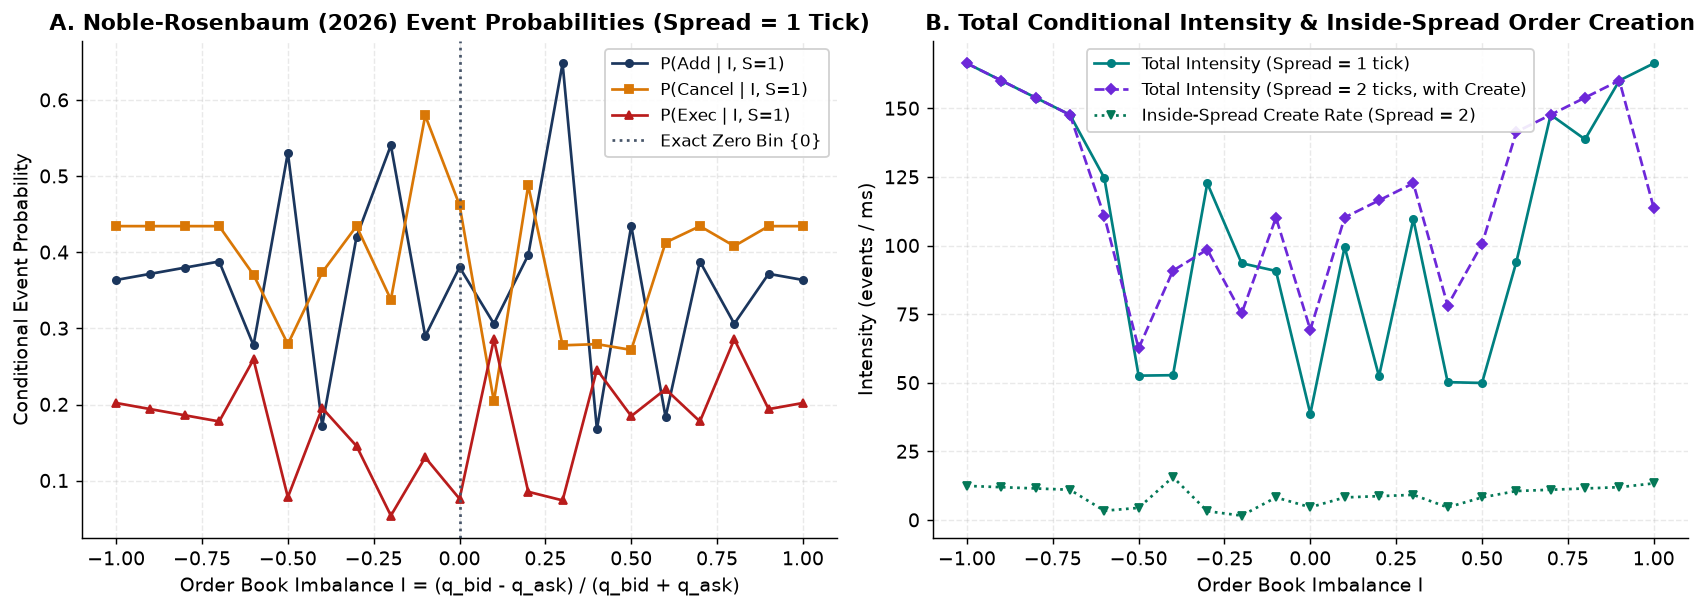

In [3]:
# Plot Noble-Rosenbaum (2026) 3D Conditional Event Probabilities & Total Intensity vs Imbalance
sub_s0_d2 = df_3d[(df_3d["spread_bin"] == 0) & (df_3d["depth_bin"] == 2)].sort_values("imbalance_bin")
sub_s1_d2 = df_3d[(df_3d["spread_bin"] == 1) & (df_3d["depth_bin"] == 2)].sort_values("imbalance_bin")
imb_centers = sub_s0_d2["imbalance_center"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8))

tot_s0 = np.maximum(1e-12, (
    sub_s0_d2["lambda_add_per_us"] + sub_s0_d2["lambda_cancel_per_us"] +
    sub_s0_d2["lambda_exec_per_us"] + sub_s0_d2["lambda_create_per_us"]
).values)
ax1.plot(imb_centers, sub_s0_d2["lambda_add_per_us"].values / tot_s0, "-o", markersize=4,
         color=qru.PALETTE["navy"], label="P(Add | I, S=1)")
ax1.plot(imb_centers, sub_s0_d2["lambda_cancel_per_us"].values / tot_s0, "-s", markersize=4,
         color=qru.PALETTE["amber"], label="P(Cancel | I, S=1)")
ax1.plot(imb_centers, sub_s0_d2["lambda_exec_per_us"].values / tot_s0, "-^", markersize=4,
         color=qru.PALETTE["crimson"], label="P(Exec | I, S=1)")
ax1.axvline(0.0, color=qru.PALETTE["slate"], linestyle=":", label="Exact Zero Bin {0}")
ax1.set_xlabel("Order Book Imbalance I = (q_bid - q_ask) / (q_bid + q_ask)")
ax1.set_ylabel("Conditional Event Probability")
ax1.set_title("A. Noble-Rosenbaum (2026) Event Probabilities (Spread = 1 Tick)")
ax1.legend()

tot_s1 = np.maximum(1e-12, (
    sub_s1_d2["lambda_add_per_us"] + sub_s1_d2["lambda_cancel_per_us"] +
    sub_s1_d2["lambda_exec_per_us"] + sub_s1_d2["lambda_create_per_us"]
).values)
ax2.plot(imb_centers, tot_s0 * 1e3, "-o", markersize=4, color=qru.PALETTE["teal"],
         label="Total Intensity (Spread = 1 tick)")
ax2.plot(imb_centers, tot_s1 * 1e3, "--D", markersize=4, color=qru.PALETTE["purple"],
         label="Total Intensity (Spread = 2 ticks, with Create)")
ax2.plot(imb_centers, sub_s1_d2["lambda_create_per_us"].values * 1e3, ":v", markersize=4,
         color=qru.PALETTE["emerald"], label="Inside-Spread Create Rate (Spread = 2)")
ax2.set_xlabel("Order Book Imbalance I")
ax2.set_ylabel("Intensity (events / ms)")
ax2.set_title("B. Total Conditional Intensity & Inside-Spread Order Creation")
ax2.legend()

plt.tight_layout()
fig_path1 = qru.FIG_DIR / "fig02_noble_rosenbaum_3d_surface.png"
plt.savefig(fig_path1, bbox_inches="tight")
plt.show()


## 2. Multi-Level Queue-Reactive + Hawkes Trajectory & Ogata Time-Rescaling Goodness-of-Fit

We now simulate `15,000` L3 order-book events using `qrlob_ffi_simulate_qr_trajectory` with:
- 5-level HLR Model IIb/III queue-reactive intensities + 6x6 Hawkes self/cross-excitation (`hawkes_scale = 0.01`),
- Inside-spread order creation and reference-price shifts (`theta_reprice = 0.65`),
- Exact Ogata thinning (`use_ogata_thinning = True`), recording the integrated conditional intensity residuals $\tau_k = \int_{t_{k-1}}^{t_k} \Lambda(s)\,\mathrm{d}s$.


In [4]:
df_qr = qru.simulate_qr_dataframe(
    num_events=15000,
    seed=20260621,
    use_3d_table=False,
    use_ogata_thinning=True,
    theta_ergodic=0.03,
    theta_reprice=0.65,
)
print(f"Simulated {len(df_qr)} multi-level QR+Hawkes events.")
display(df_qr.head(6))

residuals = df_qr["ogata_residual"].values
residuals = residuals[residuals > 0]
ks_d, ks_pval = qru.ks_statistic_exp1(residuals)
print(f"Ogata Residuals Summary: N={len(residuals)}, Mean={residuals.mean():.4f} (theoretical=1.0000), "
      f"Std={residuals.std():.4f} (theoretical=1.0000)")
print(f"Kolmogorov-Smirnov Test vs Exp(1): D = {ks_d:.4f}, p-value = {ks_pval:.4f}")
assert 0.90 <= residuals.mean() <= 1.10, "Ogata residual mean out of theoretical [0.90, 1.10] band!"


Simulated 15000 multi-level QR+Hawkes events.


,step,time_ns,best_bid,best_ask,mid,spread,bid_vol_l1,ask_vol_l1,total_bid_vol_5,total_ask_vol_5,event_kind,event_level,event_side,event_qty,price_shift,total_intensity,ogata_residual
0,0,410,99,101,100.0,2,100,100,500,500,2,1,1,21,0,0.471001,0.192691
1,1,7466,98,101,99.5,3,100,100,400,500,3,1,-1,5,0,0.471003,3.311388
2,2,7586,98,102,100.0,4,100,100,400,400,2,1,1,8,0,0.472776,0.056835
3,3,14755,97,102,99.5,5,100,100,300,400,2,1,1,38,0,0.471004,3.366413
4,4,20790,96,102,99.0,6,100,100,200,400,3,1,-1,254,1,0.471006,2.832735
5,5,22355,96,103,99.5,7,100,100,200,300,3,1,-1,37,0,0.471420,0.735616


Ogata Residuals Summary: N=15000, Mean=1.0143 (theoretical=1.0000), Std=1.0063 (theoretical=1.0000)
Kolmogorov-Smirnov Test vs Exp(1): D = 0.0111, p-value = 0.0481


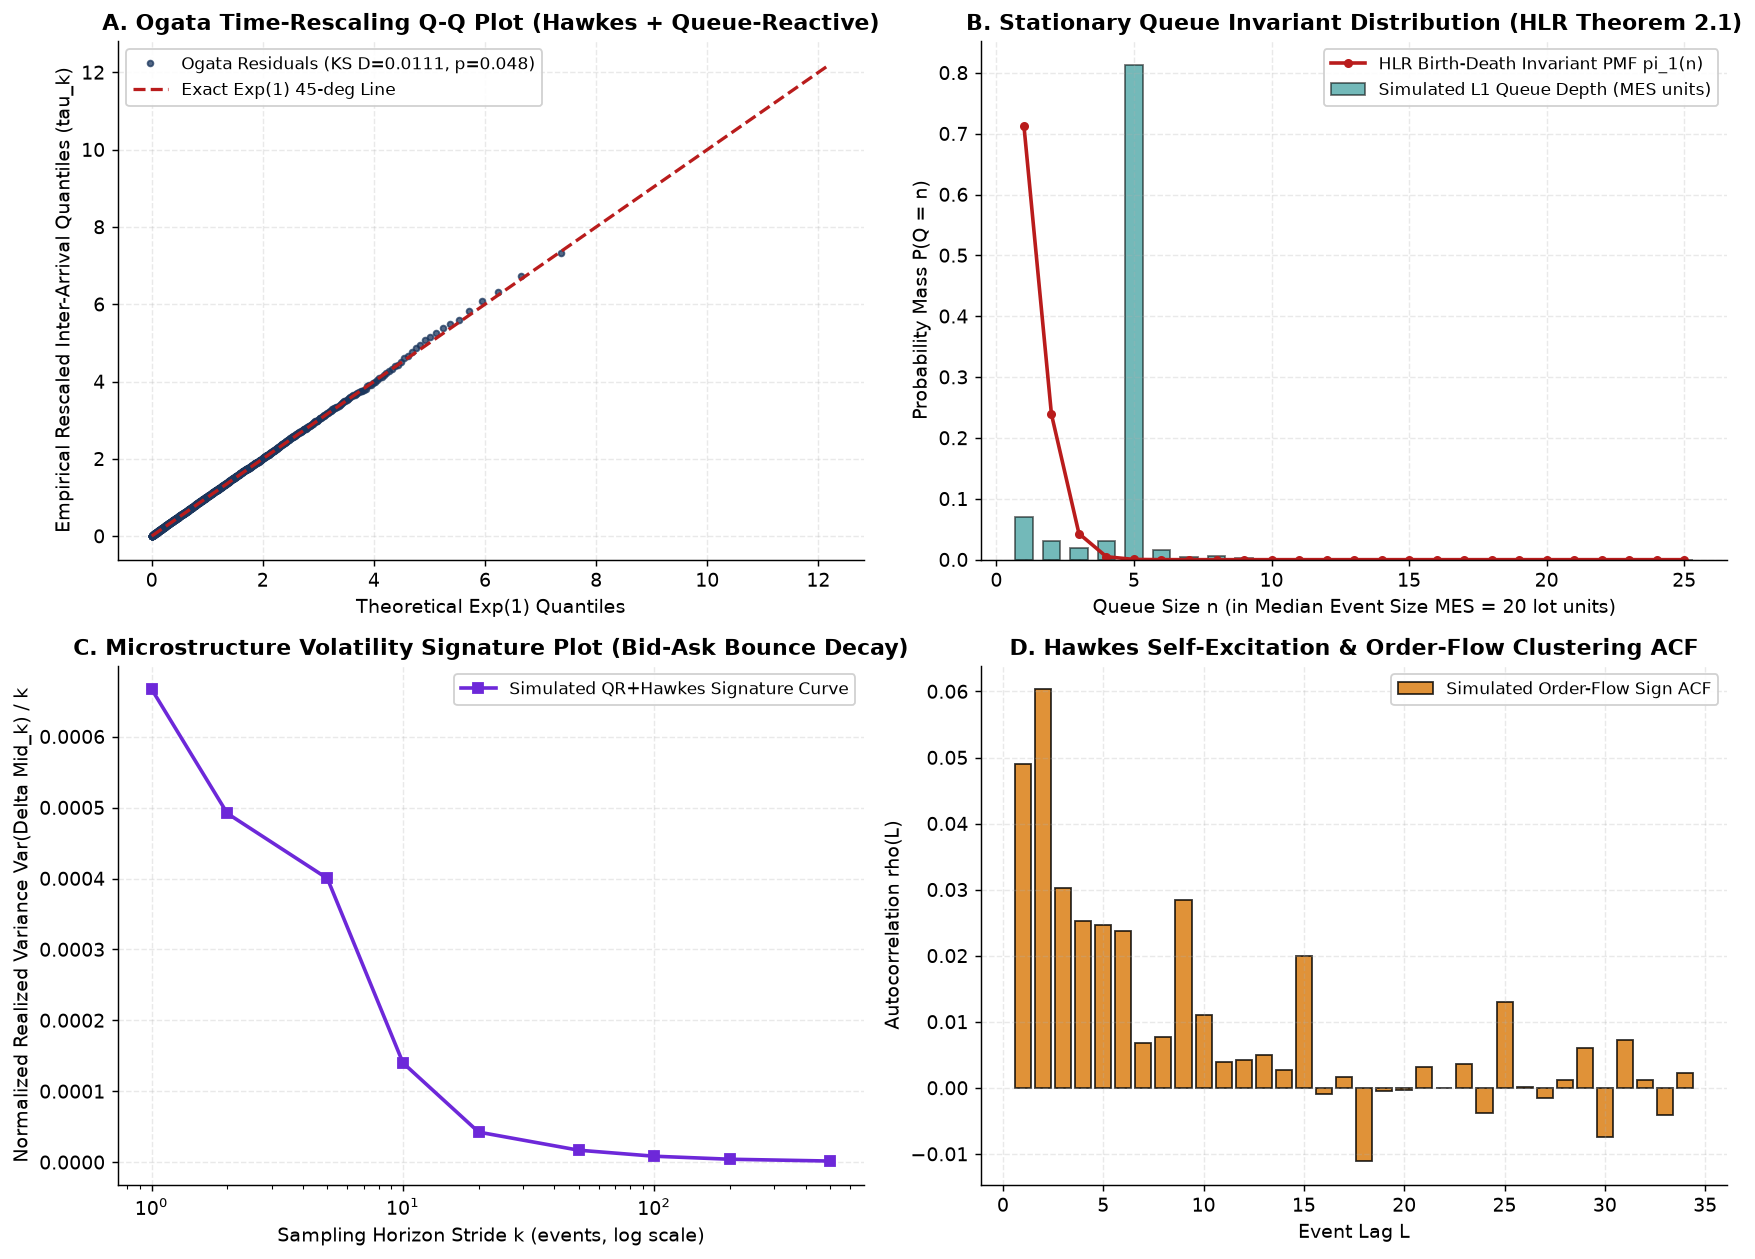

Saved figure to: /home/radu/code/queue-reactive-book/notebooks/figures/fig02_stylized_facts_and_ogata.png


In [5]:
# 4-Panel Stylized Facts & Goodness-of-Fit Figure:
# Panel A: Ogata Q-Q Plot against Exp(1)
# Panel B: Analytical Birth-Death Stationary Queue PMF vs Empirical Simulated Queue Depth
# Panel C: Microstructure Signature Plot (Realized Volatility vs Sampling Stride)
# Panel D: Order-Flow Sign Autocorrelation Decay
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.8))

# Panel A: Ogata Q-Q plot
ax = axes[0, 0]
sorted_res = np.sort(residuals)
n_res = len(sorted_res)
probs = (np.arange(1, n_res + 1) - 0.5) / n_res
theo_quantiles = -np.log(1.0 - probs)
ax.plot(theo_quantiles[::10], sorted_res[::10], "o", markersize=3.2, alpha=0.75,
        color=qru.PALETTE["navy"], label=f"Ogata Residuals (KS D={ks_d:.4f}, p={ks_pval:.3f})")
max_q = max(theo_quantiles.max(), sorted_res.max())
ax.plot([0, max_q], [0, max_q], "--", color=qru.PALETTE["crimson"], linewidth=1.8, label="Exact Exp(1) 45-deg Line")
ax.set_xlabel("Theoretical Exp(1) Quantiles")
ax.set_ylabel("Empirical Rescaled Inter-Arrival Quantiles (tau_k)")
ax.set_title("A. Ogata Time-Rescaling Q-Q Plot (Hawkes + Queue-Reactive)")
ax.legend()

# Panel B: Analytical Birth-Death Stationary Invariant PMF vs Simulated L1 Depth
ax = axes[0, 1]
pmf = qru.get_stationary_queue_pmf(64)
units_x = np.arange(1, 65)
sim_units = np.clip(np.round(df_qr["bid_vol_l1"].values / 20.0), 1, 64)
hist_vals, bin_edges = np.histogram(sim_units, bins=np.arange(0.5, 65.5, 1.0), density=True)
ax.bar(units_x[:25], hist_vals[:25], width=0.65, alpha=0.55, color=qru.PALETTE["teal"],
       edgecolor="black", label="Simulated L1 Queue Depth (MES units)")
ax.plot(units_x[:25], pmf[:25], "-o", markersize=4, linewidth=2.0, color=qru.PALETTE["crimson"],
        label="HLR Birth-Death Invariant PMF pi_1(n)")
ax.set_xlabel("Queue Size n (in Median Event Size MES = 20 lot units)")
ax.set_ylabel("Probability Mass P(Q = n)")
ax.set_title("B. Stationary Queue Invariant Distribution (HLR Theorem 2.1)")
ax.legend()

# Panel C: Microstructure Volatility Signature Plot
ax = axes[1, 0]
strides = [1, 2, 5, 10, 20, 50, 100, 200, 500]
mid_series = df_qr["mid"].values
rv_per_step = []
for k in strides:
    diffs = mid_series[k:] - mid_series[:-k]
    rv_per_step.append(np.mean(diffs ** 2) / k)
ax.plot(strides, rv_per_step, "-s", color=qru.PALETTE["purple"], linewidth=2.0, markersize=5,
        label="Simulated QR+Hawkes Signature Curve")
ax.set_xscale("log")
ax.set_xlabel("Sampling Horizon Stride k (events, log scale)")
ax.set_ylabel("Normalized Realized Variance Var(Delta Mid_k) / k")
ax.set_title("C. Microstructure Volatility Signature Plot (Bid-Ask Bounce Decay)")
ax.legend()

# Panel D: Event-Sign Autocorrelation Function (ACF)
ax = axes[1, 1]
signs = df_qr["event_side"].values.astype(float)
signs = signs - signs.mean()
var_s = np.var(signs)
lags = np.arange(1, 35)
acf = [np.mean(signs[:-L] * signs[L:]) / max(1e-12, var_s) for L in lags]
ax.bar(lags, acf, color=qru.PALETTE["amber"], edgecolor="black", alpha=0.8, label="Simulated Order-Flow Sign ACF")
ax.set_xlabel("Event Lag L")
ax.set_ylabel("Autocorrelation rho(L)")
ax.set_title("D. Hawkes Self-Excitation & Order-Flow Clustering ACF")
ax.legend()

plt.tight_layout()
fig_path2 = qru.FIG_DIR / "fig02_stylized_facts_and_ogata.png"
plt.savefig(fig_path2, bbox_inches="tight")
plt.show()
print("Saved figure to:", fig_path2)
